# Modelagem preditiva da produtividade da safra de soja com uso de aprendizado de máquina e dados agrometeorológicos — Modelagem (Etapa 3: correção da tendência)

**Integrantes:**
**Orientador:**

**Síntese do conteúdo deste arquivo:** a Etapa 2 (`modelagem_etapa2.ipynb`) mostrou que o clima por subperíodo explica ~40% da variação do rendimento, mas que as previsões de 2021–2025 ficaram enviesadas para cima porque a tendência (reta ajustada até 2020) projetava um patamar de produtividade muito acima do observado. Este notebook compara quatro formas de calcular o **patamar esperado** de cada município — reta estadual com todo o histórico, média móvel dos últimos 5 anos, média olímpica dos últimos 5 anos e reta dos últimos 10 anos —, todas usando **só safras anteriores** à prevista. Para cada patamar, o clima (lido de `dataset/processed/clima_subperiodos_estacao_safra.csv`) prevê o desvio em relação a ele, com uma OLS reduzida (uma variável por fenômeno, para coeficientes interpretáveis) e com Gradient Boosting. Avalia com o corte temporal (teste 2021–2025) e com "deixa uma safra de fora", compara com as duas linhas de base da metodologia do artigo (média histórica e safra anterior) e define o modelo final. Para o modelo final, decompõe cada previsão na contribuição de cada fator climático (equivalente ao SHAP para modelo linear) e calcula o erro por mesorregião do IBGE e por município.

| Data       | Autor           | Descrição                                                                 |
|------------|-----------------|-----------------------------------------------------------------------------|
| 2026-10-22 |                 | Criação do notebook — comparação de patamares (tendência), OLS reduzida e Gradient Boosting sobre o desvio, duas validações e escolha do modelo final |
| 2026-10-22 |                 | Linhas de base do artigo (média histórica, safra anterior), contribuição por variável (SHAP do modelo linear), erro por mesorregião e por município |
| 2026-10-24 |                 | Patamar passa a respeitar a defasagem de publicação da PAM/IBGE: para prever a safra Y em março de Y, a última safra publicada é Y−2 (janelas deslocadas; linha de base "safra anterior" vira "última safra publicada") |

## 1. Imports e configuração

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RAW = "../dataset/raw"
PROCESSED = "../dataset/processed"

ANO_CORTE = 2020      # corte temporal: modelos de clima treinados até 2020, teste 2021-2025
DEFASAGEM_PUBLICACAO = 2  # em 31/03/2026, a última PAM/IBGE publicada é a de 2024 (dois anos antes) (ver seção 3)
PRIMEIRA_SAFRA = 2006     # a partir daqui todo patamar tem pelo menos 5 safras publicadas
SEED = 42

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
print("Ambiente pronto.")

Ambiente pronto.


## 2. Dados

- Painel município–safra (rendimento, estação INMET associada, clima agregado e ONI);
- Clima por subperíodo por estação e safra, gerado na Etapa 2.

In [2]:
painel = pd.read_csv(f"{PROCESSED}/painel_municipio_safra.csv")
clima_sub = pd.read_csv(f"{PROCESSED}/clima_subperiodos_estacao_safra.csv")

ALVO = "rendimento_kg_ha"
ONI = "oni_media_safra"
CLIMA = ["chuva_out_nov", "chuva_dez_fev", "chuva_mar", "seca_max_dez_fev",
         "dias_calor_dez_fev", "tmax_dez_fev", "urmin_dez_fev"]

com_rendimento = painel.dropna(subset=[ALVO])
print(f"Linhas com rendimento: {len(com_rendimento)} | estação × safra com clima: {len(clima_sub)}")

Linhas com rendimento: 10540 | estação × safra com clima: 1125


## 3. Quatro formas de calcular o patamar esperado

O **patamar** é o rendimento que se espera do município numa safra "normal", antes de
olhar o clima. Ele só pode usar o rendimento **já publicado na data da previsão** (31 de
março do ano da colheita: 31/03/2026 para a safra 2026).

**Defasagem de publicação.** O rendimento municipal vem da Produção Agrícola Municipal
(PAM, tabela 1612 do SIDRA), que o IBGE divulga em setembro **do ano seguinte** à
colheita — a PAM 2024, por exemplo, saiu em 11/09/2025. Assim, em 31/03/2026 a última
safra publicada é a de **2024** (PAM de set/2025): o rendimento de 2025 só saiu em set/2026, seis meses
depois da previsão. Exemplo para o uso do modelo nas próximas safras:

| Safra prevista | Emissão da previsão | Última PAM publicada | Janela do patamar (5 anos) |
|---|---|---|---|
| 2026 | 31/03/2026 | 2024 (set/2025) | 2020–2024 |
| 2027 | 31/03/2027 | 2025 (set/2026) | 2021–2025 |
| 2028 | 31/03/2028 | 2026 (set/2027) | 2022–2026 |

Usar a safra anterior (por exemplo, a média de 2021–2025 para prever 2026) daria ao modelo um dado que
ainda não existe no momento da previsão. Por isso todas as janelas abaixo terminam na
última safra publicada, dois anos antes da safra prevista (2024 para prever 2026; constante `DEFASAGEM_PUBLICACAO`). O efeito dessa escolha sobre o desempenho é
medido na seção 9 de `modelagem_etapa4.ipynb`.

| Patamar | Como é calculado | Ideia |
|---|---|---|
| **Reta estadual (histórico todo)** | reta ajustada às médias estaduais de 2000 até a última safra publicada (2000–2024 para prever 2026), projetada para a safra prevista, + diferença média do município em relação ao estado | É a abordagem da Etapa 2, agora atualizada a cada safra |
| **Média móvel 5 anos** | média do rendimento do município nas 5 últimas safras publicadas (2020–2024 para prever 2026) | Acompanha o patamar recente, sem extrapolar |
| **Média olímpica 5 anos** | média das mesmas 5 safras (2020–2024 para prever 2026) descartando o melhor e o pior ano | Usada em seguro agrícola: um ano de seca ou recorde isolado não distorce o patamar |
| **Reta dos últimos 10 anos** | reta das médias estaduais das 10 últimas safras publicadas (2015–2024 para prever 2026) projetada para a safra prevista, + diferença média do município nesses anos | Tendência, mas que se adapta a mudanças recentes |

Regras: o município precisa de pelo menos 3 safras com rendimento na janela (5 para a
média olímpica descartar extremos; com 3 ou 4, usa a média simples). Sem isso, usa o
valor equivalente calculado com as médias do estado. A média estadual é a média simples
dos municípios com rendimento em cada safra.

Também são calculadas as **duas linhas de base previstas na metodologia do artigo**,
usadas como régua (sem clima):

- **Média histórica** — média do rendimento do município em todas as safras publicadas
  (até 2024 para prever 2026; mínimo de 3; senão, média estadual dessas safras);
- **Última safra publicada** — rendimento do município na última safra publicada (2024 para prever
  2026; sem dado, usa a média estadual dessa safra). É a versão operacional da linha de base "safra anterior" da
  metodologia.

In [3]:
rend = com_rendimento.pivot_table(index="ano_safra", columns="codigo_ibge_municipio",
                                  values=ALVO)
estado = rend.mean(axis=1)


def media_olimpica(janela, n):
    # descarta o maior e o menor valor quando há pelo menos 5 safras; senão, média simples
    olimpica = (janela.sum() - janela.max() - janela.min()) / (n - 2)
    return olimpica.where(n >= 5, janela.mean())


def reta_projetada(serie, ano):
    coef = np.polyfit(serie.index, serie.to_numpy(), 1)
    return np.polyval(coef, ano)


def diferenca_municipio(janela):
    dif = janela.sub(estado.loc[janela.index], axis=0)
    return dif.mean().where(dif.count() >= 3, 0.0)


partes = []
for ano in range(PRIMEIRA_SAFRA, int(rend.index.max()) + 1):
    ultima = ano - DEFASAGEM_PUBLICACAO   # última safra publicada em março de `ano`
    j5 = rend.loc[ultima - 4:ultima]
    n5 = j5.count()
    e5 = estado.loc[ultima - 4:ultima]
    j10 = rend.loc[ultima - 9:ultima]
    todos = rend.loc[:ultima]
    partes.append(pd.DataFrame({
        "ano_safra": ano,
        "patamar_reta": reta_projetada(estado.loc[:ultima], ano) + diferenca_municipio(todos),
        "patamar_mm5": j5.mean().where(n5 >= 3, e5.mean()),
        "patamar_olimpica5": media_olimpica(j5, n5).where(n5 >= 3, (e5.sum() - e5.max() - e5.min()) / 3),
        "patamar_reta10": reta_projetada(estado.loc[ultima - 9:ultima], ano) + diferenca_municipio(j10),
        "base_media_hist": todos.mean().where(todos.count() >= 3, estado.loc[:ultima].mean()),
        "base_safra_anterior": rend.loc[ultima].fillna(estado.loc[ultima]),
    }))
patamares = (pd.concat(partes).rename_axis("codigo_ibge_municipio").reset_index())

PATAMARES = {"patamar_reta": "Reta estadual (histórico todo)",
             "patamar_mm5": "Média móvel 5 anos",
             "patamar_olimpica5": "Média olímpica 5 anos",
             "patamar_reta10": "Reta dos últimos 10 anos"}
LINHAS_BASE = {"base_media_hist": "Linha de base: média histórica",
               "base_safra_anterior": "Linha de base: última safra publicada"}
NOMES = {**PATAMARES, **LINHAS_BASE}
print(f"Patamares calculados: {len(patamares)} linhas (município × safra, {PRIMEIRA_SAFRA}–{int(rend.index.max())})")

Patamares calculados: 9080 linhas (município × safra, 2006–2025)


### Patamar estadual × rendimento observado

Antes de qualquer clima: como cada patamar se compara ao rendimento médio do estado? O
patamar ideal acompanha o nível "normal" da produtividade sem tentar prever secas — as
quedas abaixo dele são o que o clima deve explicar.

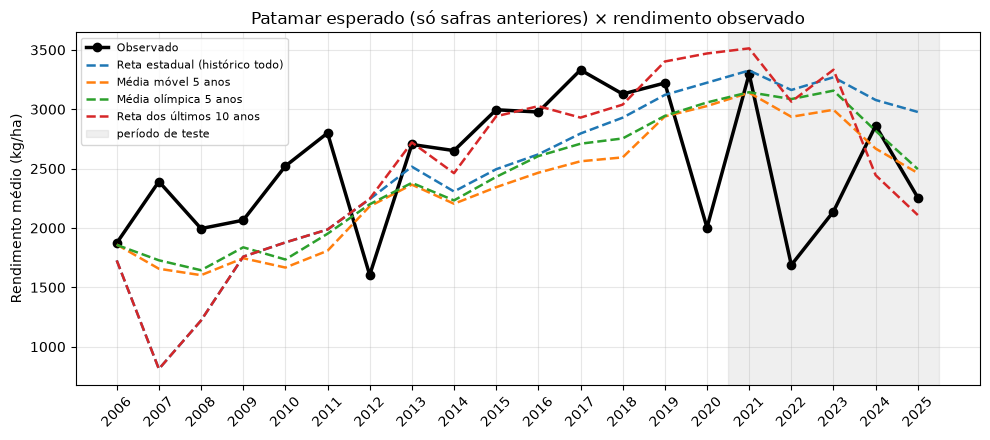

,rendimento_kg_ha,patamar_reta,patamar_mm5,patamar_olimpica5,patamar_reta10
ano_safra,,,,,
2018,"3,128.00","2,929.00","2,595.00","2,754.00","3,039.00"
2019,"3,221.00","3,121.00","2,939.00","2,944.00","3,402.00"
2020,"2,003.00","3,224.00","3,027.00","3,057.00","3,470.00"
2021,"3,297.00","3,327.00","3,139.00","3,144.00","3,513.00"
2022,"1,688.00","3,162.00","2,936.00","3,086.00","3,064.00"
2023,"2,139.00","3,269.00","2,996.00","3,157.00","3,333.00"
2024,"2,862.00","3,078.00","2,668.00","2,818.00","2,445.00"
2025,"2,256.00","2,977.00","2,463.00","2,496.00","2,109.00"


In [4]:
pat_estado = (patamares.merge(com_rendimento[["codigo_ibge_municipio", "ano_safra", ALVO]],
                              on=["codigo_ibge_municipio", "ano_safra"])
              .groupby("ano_safra")[[ALVO] + list(PATAMARES)].mean())

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(pat_estado.index, pat_estado[ALVO], "k-o", lw=2.5, label="Observado")
for col, nome in PATAMARES.items():
    ax.plot(pat_estado.index, pat_estado[col], "--", lw=1.8, label=nome)
ax.axvspan(ANO_CORTE + 0.5, pat_estado.index.max() + 0.5, color="grey", alpha=0.12,
           label="período de teste")
ax.set_xticks(pat_estado.index)
ax.tick_params(axis="x", rotation=45)
ax.set_ylabel("Rendimento médio (kg/ha)")
ax.set_title("Patamar esperado (só safras anteriores) × rendimento observado")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
pat_estado.loc[2018:].round(0)

## 4. Base de modelagem

Linhas com rendimento, patamares e todas as variáveis climáticas, a partir de 2006.

In [5]:
base = (painel.merge(clima_sub, on=["codigo_estacao", "ano_safra"], how="left")
        .merge(patamares, on=["codigo_ibge_municipio", "ano_safra"], how="left"))
base = base.dropna(subset=[ALVO, ONI] + CLIMA + list(NOMES)).copy()
base = base[base["ano_safra"] >= PRIMEIRA_SAFRA]
print(f"Linhas: {len(base)} | municípios: {base['codigo_ibge_municipio'].nunique()} | "
      f"safras: {base['ano_safra'].min()}–{base['ano_safra'].max()}")
print(f"  treino (<= {ANO_CORTE}): {(base['ano_safra'] <= ANO_CORTE).sum()} | "
      f"teste (> {ANO_CORTE}): {(base['ano_safra'] > ANO_CORTE).sum()}")

Linhas: 5236 | municípios: 448 | safras: 2006–2025
  treino (<= 2020): 3645 | teste (> 2020): 1591


## 5. Modelos

Para cada patamar, três previsões:

1. **Só patamar** — sem clima. Mede quão bom é o patamar sozinho.
2. **Patamar + OLS reduzida** — a OLS prevê o desvio (rendimento − patamar) com **uma
   variável por fenômeno**, para eliminar a colinearidade que gerou sinais sem sentido
   na Etapa 2 (temperatura máxima positiva, ONI negativo):
   - `chuva_out_nov` — chuva na semeadura;
   - `chuva_dez_fev` e seu quadrado — chuva no período crítico, com ganho decrescente;
   - `chuva_mar` — chuva no fim do enchimento;
   - `dias_calor_dez_fev` — estresse térmico (no lugar da temperatura máxima média);
   - `urmin_dez_fev` — secura do ar (no lugar da sequência seca, que perdeu
     significância na Etapa 2).
   O ONI fica de fora: o efeito do El Niño já chega ao modelo pela chuva e pela umidade.
3. **Patamar + Gradient Boosting** — prevê o desvio com todas as variáveis climáticas e
   o ONI.

Previsão final = patamar + desvio previsto.

As duas linhas de base (média histórica e última safra publicada) entram nas tabelas como
previsões sem clima, para comparação.

In [6]:
FEAT_OLS = ["chuva_out_nov_100", "chuva_dez_fev_c100", "chuva_dez_fev_c100_2", "chuva_mar_100",
            "dias_calor_dez_fev", "urmin_dez_fev"]
FEAT_GB = CLIMA + [ONI]


def derivar(d, media_dez_fev):
    d = d.copy()
    d["chuva_out_nov_100"] = d["chuva_out_nov"] / 100
    d["chuva_dez_fev_c100"] = (d["chuva_dez_fev"] - media_dez_fev) / 100
    d["chuva_dez_fev_c100_2"] = d["chuva_dez_fev_c100"] ** 2
    d["chuva_mar_100"] = d["chuva_mar"] / 100
    return d


def gb():
    return HistGradientBoostingRegressor(learning_rate=0.05, max_iter=500, min_samples_leaf=20,
                                         early_stopping=True, validation_fraction=0.1,
                                         random_state=SEED)


def prever_todos(tr, te):
    # Devolve {(patamar, modelo): previsão} para todas as combinações
    media = tr["chuva_dez_fev"].mean()
    tr, te = derivar(tr, media), derivar(te, media)
    saida = {(col, "Sem clima"): te[col].to_numpy() for col in LINHAS_BASE}
    for pat in PATAMARES:
        desvio = tr[ALVO] - tr[pat]
        saida[(pat, "Só patamar")] = te[pat].to_numpy()
        ols = LinearRegression().fit(tr[FEAT_OLS], desvio)
        saida[(pat, "+ OLS reduzida")] = te[pat].to_numpy() + ols.predict(te[FEAT_OLS])
        modelo_gb = gb().fit(tr[FEAT_GB], desvio)
        saida[(pat, "+ Gradient Boosting")] = te[pat].to_numpy() + modelo_gb.predict(te[FEAT_GB])
    return saida


def metricas(y, pred):
    return {"RMSE (kg/ha)": mean_squared_error(y, pred) ** 0.5,
            "MAE (kg/ha)": mean_absolute_error(y, pred),
            "R²": r2_score(y, pred),
            "Viés (kg/ha)": np.mean(pred - y)}


def tabela(y, previsoes):
    t = pd.DataFrame({k: metricas(y, p) for k, p in previsoes.items()}).T
    t.index = pd.MultiIndex.from_tuples([(NOMES[p], m) for p, m in t.index],
                                        names=["patamar", "modelo"])
    return t


FORMATO = {"RMSE (kg/ha)": "{:.0f}", "MAE (kg/ha)": "{:.0f}", "R²": "{:.3f}",
           "Viés (kg/ha)": "{:+.0f}"}
print("Combinações:", len(PATAMARES) * 3 + len(LINHAS_BASE))

Combinações: 14


## 6. Validação 1 — corte temporal (treino até 2020, teste 2021–2025)

O modelo de clima é treinado só até 2020. O patamar de cada safra de teste usa as safras
já publicadas em março daquele ano (por exemplo, o patamar de 2023 conhece o rendimento
de 2021, publicado em set/2022, mas não o de 2022), como aconteceria na prática.

Observação: para a safra 2021, a rigor, o rendimento de 2020 ainda não estaria publicado
em março de 2021, e ele entra no treino do modelo de clima. O efeito é limitado aos
coeficientes do clima (não ao patamar) e a uma das cinco safras de teste.

Referência da Etapa 2 neste mesmo teste (base um pouco diferente): melhor modelo com
RMSE ≈ 815 kg/ha, R² ≈ 0,15 e viés de +216 kg/ha; o Gradient Boosting teve RMSE ≈ 1.015
e viés de +717 kg/ha.

In [7]:
treino = base[base["ano_safra"] <= ANO_CORTE]
teste = base[base["ano_safra"] > ANO_CORTE]
prev_corte = prever_todos(treino, teste)
corte = tabela(teste[ALVO], prev_corte)
print(f"Teste: {len(teste)} linhas | rendimento médio {teste[ALVO].mean():.0f} kg/ha")
corte.style.format(FORMATO).highlight_min(subset=["RMSE (kg/ha)"], color="#c6efce")

Teste: 1591 linhas | rendimento médio 2497 kg/ha


## 7. Validação 2 — deixa uma safra de fora (2008–2025)

O modelo de clima de cada rodada é treinado com todas as outras safras. O patamar
continua usando só safras já publicadas (não depende da validação). Treinar o
clima com safras posteriores é próprio desta validação: ela mede a estabilidade da
relação clima × rendimento entre safras, não simula a previsão em tempo real.

Referência da Etapa 2: melhor modelo com RMSE ≈ 591 kg/ha e R² ≈ 0,44. **Atenção:** esse
número não é diretamente comparável e era otimista. Na Etapa 2, a tendência e o efeito
do município de cada rodada eram calculados com todas as outras safras, **inclusive as
posteriores** à safra prevista — para prever 2012, o modelo já "conhecia" o patamar de
2013–2025, informação que nunca está disponível na prática. Aqui o patamar usa só o
que já estava publicado, então os valores abaixo são a medida realista.

In [8]:
anos_loyo = [a for a in sorted(base["ano_safra"].unique()) if a >= 2008]
partes = []
for ano in anos_loyo:
    tr, te = base[base["ano_safra"] != ano], base[base["ano_safra"] == ano]
    p = prever_todos(tr, te)
    partes.append(te[["codigo_ibge_municipio", "ano_safra", ALVO]]
                  .assign(**{f"{a}|{b}": v for (a, b), v in p.items()}))
loyo = pd.concat(partes, ignore_index=True)
prev_loyo = {tuple(c.split("|")): loyo[c].to_numpy() for c in loyo.columns if "|" in c}
geral = tabela(loyo[ALVO], prev_loyo)
print(f"{len(anos_loyo)} safras, {len(loyo)} linhas")
geral.style.format(FORMATO).highlight_min(subset=["RMSE (kg/ha)"], color="#c6efce")

18 safras, 5125 linhas


## 8. Resumo lado a lado e escolha do modelo final

O modelo final deve ser bom **nas duas validações**: no corte temporal (simula a
previsão real nas safras mais recentes) e no "deixa uma safra de fora" (estabilidade
entre safras). O critério é a média do RMSE nas duas.

In [9]:
resumo = pd.concat({"Corte 2021–2025": corte[["RMSE (kg/ha)", "R²", "Viés (kg/ha)"]],
                    "Deixa uma safra de fora": geral[["RMSE (kg/ha)", "R²", "Viés (kg/ha)"]]},
                   axis=1)
resumo[("Média", "RMSE (kg/ha)")] = (resumo[("Corte 2021–2025", "RMSE (kg/ha)")]
                                     + resumo[("Deixa uma safra de fora", "RMSE (kg/ha)")]) / 2
resumo = resumo.sort_values(("Média", "RMSE (kg/ha)"))
FINAL = resumo.index[0]
print("Modelo final (menor RMSE médio):", " ".join(FINAL))
resumo.style.format("{:.0f}").format("{:.3f}", subset=[c for c in resumo.columns if c[1] == "R²"])

Modelo final (menor RMSE médio): Média móvel 5 anos + OLS reduzida


## 9. Modelo final — safra a safra

Rendimento médio do estado por safra: observado × previsto pelo modelo final, nas duas
validações, com a previsão "só patamar" do mesmo patamar para mostrar quanto o clima
acrescenta.

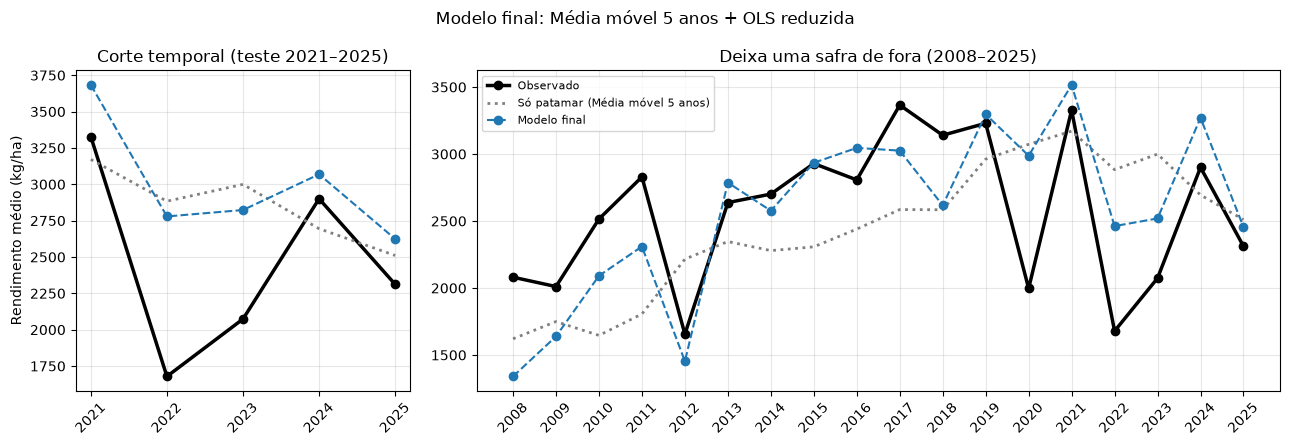

,MAE da média estadual (kg/ha),correlação com o observado
Corte 2021–2025,537.30,0.84
Deixa uma safra de fora,368.26,0.70


,rendimento_kg_ha,final,patamar
ano_safra,,,
2021,"3,328.00","3,684.00","3,171.00"
2022,"1,679.00","2,779.00","2,883.00"
2023,"2,074.00","2,823.00","2,999.00"
2024,"2,900.00","3,069.00","2,695.00"
2025,"2,312.00","2,624.00","2,511.00"


In [10]:
pat_final = {v: k for k, v in NOMES.items()}[FINAL[0]]
chave_final, chave_pat = (pat_final, FINAL[1]), (pat_final, "Só patamar")

estado_corte = (teste[["ano_safra", ALVO]]
                .assign(final=prev_corte[chave_final], patamar=prev_corte[chave_pat])
                .groupby("ano_safra").mean())
estado_loyo = (loyo[["ano_safra", ALVO]]
               .assign(final=prev_loyo[chave_final], patamar=prev_loyo[chave_pat])
               .groupby("ano_safra").mean())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 2.4]})
for ax, dados, titulo in [(axes[0], estado_corte, "Corte temporal (teste 2021–2025)"),
                          (axes[1], estado_loyo, "Deixa uma safra de fora (2008–2025)")]:
    ax.plot(dados.index, dados[ALVO], "k-o", lw=2.5, label="Observado")
    ax.plot(dados.index, dados["patamar"], ":", color="grey", lw=2, label=f"Só patamar ({FINAL[0]})")
    ax.plot(dados.index, dados["final"], "--o", color="tab:blue", label="Modelo final")
    ax.set_xticks(dados.index)
    ax.tick_params(axis="x", rotation=45)
    ax.set_title(titulo)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Rendimento médio (kg/ha)")
axes[1].legend(fontsize=8)
fig.suptitle(f"Modelo final: {' '.join(FINAL)}")
plt.tight_layout()
plt.show()

erro_estado = pd.DataFrame({
    "MAE da média estadual (kg/ha)": [(estado_corte["final"] - estado_corte[ALVO]).abs().mean(),
                                      (estado_loyo["final"] - estado_loyo[ALVO]).abs().mean()],
    "correlação com o observado": [estado_corte["final"].corr(estado_corte[ALVO]),
                                   estado_loyo["final"].corr(estado_loyo[ALVO])]},
    index=["Corte 2021–2025", "Deixa uma safra de fora"])
display(erro_estado.round(2))
estado_corte.round(0)

## 10. Coeficientes da OLS reduzida

Ajustada com todas as safras da base (2006–2025) sobre o desvio em relação ao patamar
final. Com uma variável por fenômeno, os sinais devem ser coerentes com a agronomia.
Mesma ressalva das etapas anteriores: os p-valores tendem a ser otimistas porque linhas
da mesma safra são correlacionadas.

In [11]:
def tabela_ols(modelo, X, y):
    Xc = np.column_stack([np.ones(len(X)), X.to_numpy(dtype=float)])
    beta = np.r_[modelo.intercept_, modelo.coef_]
    residuos = y.to_numpy() - Xc @ beta
    gl = len(y) - Xc.shape[1]
    ep = np.sqrt(np.diag(residuos @ residuos / gl * np.linalg.inv(Xc.T @ Xc)))
    t = beta / ep
    return pd.DataFrame({"coeficiente": beta, "erro_padrao": ep, "t": t,
                         "p_valor": 2 * stats.t.sf(np.abs(t), gl)},
                        index=["intercepto"] + list(X.columns))


completa = derivar(base, base["chuva_dez_fev"].mean())
desvio_final = completa[ALVO] - completa[pat_final]
ols_final = LinearRegression().fit(completa[FEAT_OLS], desvio_final)
print(f"Patamar: {FINAL[0]} | chuva média de dez–fev: {base['chuva_dez_fev'].mean():.0f} mm")
print("Correlação entre as variáveis da OLS reduzida (maior |r| fora da diagonal):",
      f"{completa[FEAT_OLS].drop(columns='chuva_dez_fev_c100_2').corr().abs().where(lambda m: m < 1).max().max():.2f}")
tabela_ols(ols_final, completa[FEAT_OLS], desvio_final)

Patamar: Média móvel 5 anos | chuva média de dez–fev: 418 mm
Correlação entre as variáveis da OLS reduzida (maior |r| fora da diagonal): 0.63


,coeficiente,erro_padrao,t,p_valor
intercepto,"-1,227.12",102.28,-12.00,0.00
chuva_out_nov_100,-8.16,5.19,-1.57,0.12
chuva_dez_fev_c100,220.89,8.10,27.27,0.00
chuva_dez_fev_c100_2,-39.03,2.59,-15.10,0.00
chuva_mar_100,46.70,12.49,3.74,0.00
dias_calor_dez_fev,-4.11,0.74,-5.54,0.00
urmin_dez_fev,31.85,1.95,16.37,0.00


**Como ler:** cada coeficiente é o efeito sobre o desvio do rendimento em relação ao
patamar do município (kg/ha). `chuva_*_100`: +100 mm no subperíodo;
`chuva_dez_fev_c100`: +100 mm em dez–fev a partir da média, e o termo quadrático indica
se o ganho diminui com chuva excessiva; `dias_calor_dez_fev`: cada dia a mais com
máxima ≥ 32 °C; `urmin_dez_fev`: cada ponto percentual a mais de umidade mínima.

## 11. Por que o modelo previu cada safra? (contribuição de cada variável)

A metodologia do artigo previa aplicar **SHAP** ao melhor modelo para identificar os
fatores mais relevantes. Para um modelo linear, o valor SHAP de uma variável numa
previsão tem forma exata: **coeficiente × (valor − média da variável)** (Lundberg e Lee,
2017, para variáveis tratadas como independentes). Por isso não é preciso a biblioteca
`shap`: a decomposição abaixo é o próprio SHAP do modelo final.

Cada barra mostra, para a média dos municípios em cada safra, quantos kg/ha cada fator
climático somou ou tirou em relação a uma safra de clima médio. Os dois termos da chuva
de dez–fev (linear e quadrático) foram somados num único fator. O losango é a soma das
contribuições (desvio previsto) e o círculo é o desvio observado, ambos medidos em
relação à média.

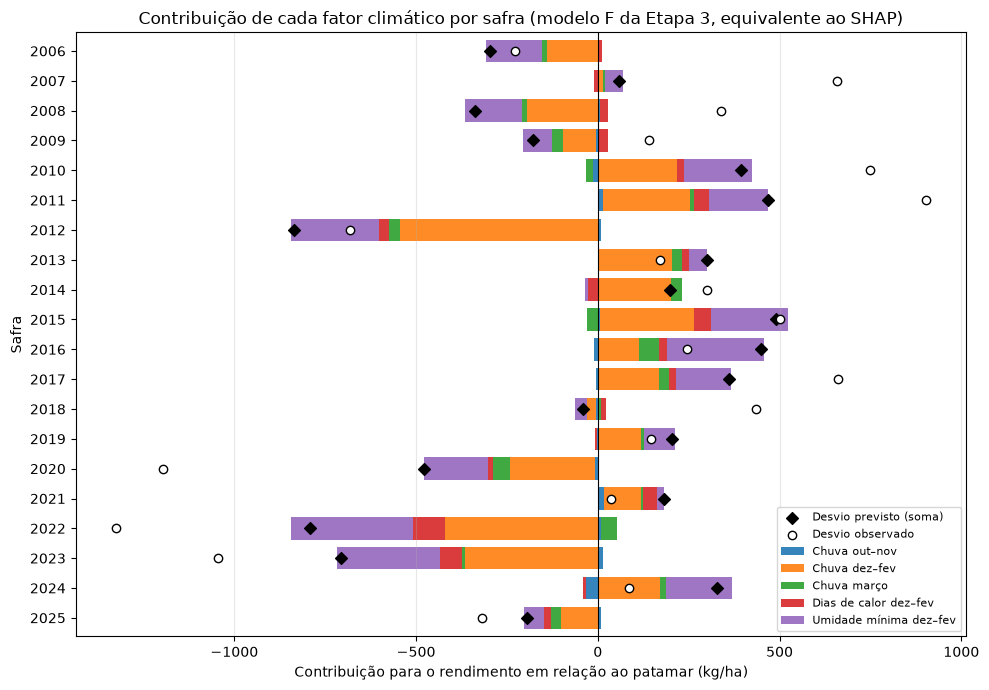

Importância média (média do |contribuição|, kg/ha):
Chuva dez–fev            263.00
Umidade mínima dez–fev   178.00
Dias de calor dez–fev     55.00
Chuva março               29.00
Chuva out–nov             11.00


,Chuva out–nov,Chuva dez–fev,Chuva março,Dias de calor dez–fev,Umidade mínima dez–fev,Desvio previsto,Desvio observado
ano_safra,,,,,,,
2012,8.00,-544.00,-30.00,-28.00,-241.00,-835.00,-680.00
2020,-7.00,-234.00,-48.00,-14.00,-174.00,-478.00,"-1,196.00"
2021,17.00,103.00,3.00,38.00,21.00,183.00,36.00
2022,10.00,-421.00,42.00,-87.00,-337.00,-793.00,"-1,325.00"
2023,13.00,-366.00,-7.00,-60.00,-284.00,-705.00,"-1,046.00"
2024,-32.00,171.00,15.00,-8.00,181.00,328.00,86.00
2025,9.00,-102.00,-27.00,-20.00,-54.00,-194.00,-319.00


In [12]:
coef = pd.Series(ols_final.coef_, index=FEAT_OLS)
contrib = completa[FEAT_OLS].sub(completa[FEAT_OLS].mean()).mul(coef)
FATORES = {"Chuva out–nov": ["chuva_out_nov_100"],
           "Chuva dez–fev": ["chuva_dez_fev_c100", "chuva_dez_fev_c100_2"],
           "Chuva março": ["chuva_mar_100"],
           "Dias de calor dez–fev": ["dias_calor_dez_fev"],
           "Umidade mínima dez–fev": ["urmin_dez_fev"]}
contrib = pd.DataFrame({f: contrib[cols].sum(axis=1) for f, cols in FATORES.items()})

por_safra_contrib = contrib.groupby(completa["ano_safra"]).mean()
por_safra_contrib["Desvio previsto"] = por_safra_contrib[list(FATORES)].sum(axis=1)
por_safra_contrib["Desvio observado"] = ((desvio_final - desvio_final.mean())
                                         .groupby(completa["ano_safra"]).mean())

fig, ax = plt.subplots(figsize=(10, 7))
por_safra_contrib[list(FATORES)].plot.barh(stacked=True, ax=ax, width=0.75, alpha=0.9)
y = np.arange(len(por_safra_contrib))
ax.scatter(por_safra_contrib["Desvio previsto"], y, marker="D", color="k", zorder=3,
           label="Desvio previsto (soma)")
ax.scatter(por_safra_contrib["Desvio observado"], y, marker="o", facecolor="white",
           edgecolor="k", zorder=3, label="Desvio observado")
ax.axvline(0, color="k", lw=0.8)
ax.invert_yaxis()
ax.set_xlabel("Contribuição para o rendimento em relação ao patamar (kg/ha)")
ax.set_ylabel("Safra")
ax.set_title("Contribuição de cada fator climático por safra (modelo F da Etapa 3, equivalente ao SHAP)")
ax.grid(axis="x", alpha=0.3)
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

importancia_media = contrib.abs().mean().sort_values(ascending=False)
print("Importância média (média do |contribuição|, kg/ha):")
print(importancia_media.round(0).to_string())
por_safra_contrib.loc[[2012, 2020, 2021, 2022, 2023, 2024, 2025]].round(0)

## 12. Erro por região (mesorregiões do IBGE)

A metodologia previa métricas por região. Os municípios foram agrupados nas sete
mesorregiões geográficas do IBGE (tabela em `dataset/raw/ibge_municipios_rs_regioes.csv`,
obtida da API de localidades do IBGE). O erro relativo (MAE %) divide o erro absoluto
médio pelo rendimento médio observado da região, para comparar regiões com níveis de
produtividade diferentes. Os resultados são do modelo final nas duas validações.

Deixa uma safra de fora (2008–2025):


,linhas,municípios,rendimento médio (kg/ha),MAE (kg/ha),viés (kg/ha),MAE %
mesorregiao,,,,,,
Noroeste,2796,216,2708,552,+5,20.4%
Centro Oriental,526,53,2589,546,-16,21.1%
Metropolitana de Porto Alegre,467,60,2365,581,+216,24.6%
Nordeste,462,44,2994,563,+191,18.8%
Centro Ocidental,355,31,2337,544,+152,23.3%
Sudeste,269,25,2170,602,+67,27.7%
Sudoeste,250,19,1988,600,-237,30.2%


Corte temporal (teste 2021–2025):


,linhas,municípios,rendimento médio (kg/ha),MAE (kg/ha),viés (kg/ha),MAE %
mesorregiao,,,,,,
Noroeste,806,216,2622,741,+589,28.3%
Nordeste,189,43,2897,760,+524,26.2%
Centro Oriental,174,52,2432,555,+318,22.8%
Metropolitana de Porto Alegre,158,55,2317,641,+369,27.7%
Centro Ocidental,101,31,1819,759,+654,41.7%
Sudeste,90,25,2325,622,+195,26.8%
Sudoeste,73,19,1771,504,+285,28.5%


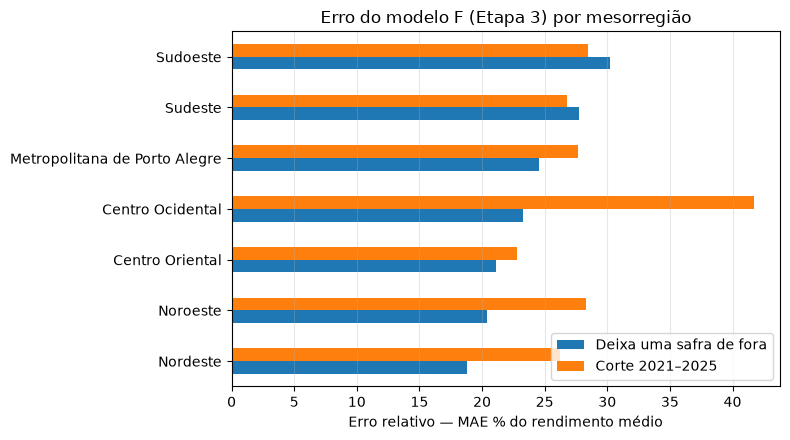

In [13]:
regioes = pd.read_csv(f"{RAW}/ibge_municipios_rs_regioes.csv",
                      usecols=["codigo_ibge_municipio", "mesorregiao"])
regioes["mesorregiao"] = regioes["mesorregiao"].str.replace(" Rio-grandense", "")


def erro_por_grupo(dados, previsao, grupo):
    d = dados.assign(previsto=previsao, erro=previsao - dados[ALVO])
    g = d.groupby(grupo)
    t = pd.DataFrame({
        "linhas": g.size(),
        "municípios": g["codigo_ibge_municipio"].nunique(),
        "rendimento médio (kg/ha)": g[ALVO].mean(),
        "MAE (kg/ha)": g["erro"].apply(lambda e: e.abs().mean()),
        "viés (kg/ha)": g["erro"].mean(),
    })
    t["MAE %"] = t["MAE (kg/ha)"] / t["rendimento médio (kg/ha)"]
    return t


reg_corte = erro_por_grupo(teste.merge(regioes, on="codigo_ibge_municipio", how="left"),
                           prev_corte[chave_final], "mesorregiao")
reg_loyo = erro_por_grupo(loyo.merge(regioes, on="codigo_ibge_municipio", how="left"),
                          prev_loyo[chave_final], "mesorregiao")
FORMATO_REG = {"rendimento médio (kg/ha)": "{:.0f}", "MAE (kg/ha)": "{:.0f}",
               "viés (kg/ha)": "{:+.0f}", "MAE %": "{:.1%}"}
print("Deixa uma safra de fora (2008–2025):")
display(reg_loyo.sort_values("linhas", ascending=False).style.format(FORMATO_REG))
print("Corte temporal (teste 2021–2025):")
display(reg_corte.sort_values("linhas", ascending=False).style.format(FORMATO_REG))

ordem = reg_loyo.sort_values("MAE %").index
ax = pd.DataFrame({"Deixa uma safra de fora": reg_loyo["MAE %"],
                   "Corte 2021–2025": reg_corte["MAE %"]}).loc[ordem].mul(100).plot.barh(figsize=(8, 4.5))
ax.set_xlabel("Erro relativo — MAE % do rendimento médio")
ax.set_ylabel("")
ax.set_title("Erro do modelo F (Etapa 3) por mesorregião")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 13. Erro por município

Com a validação "deixa uma safra de fora", cada município tem várias safras previstas
sem ter sido visto. Considerando os municípios com pelo menos 8 safras avaliadas,
calculamos o erro relativo (MAE %) de cada um.

Municípios com >= 8 safras avaliadas: 375
Distribuição do MAE % por município:
mean    22.3%
std      7.0%
min      7.5%
10%     13.9%
25%     17.0%
50%     21.2%
75%     27.1%
90%     32.7%
max     42.3%


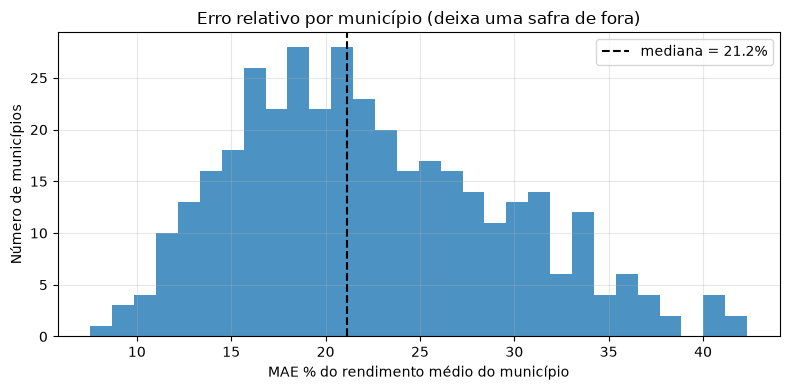

Correlação entre rendimento médio e MAE % dos municípios: -0.62

5 municípios com menor erro relativo:


,municipio,mesorregiao,linhas,rendimento médio (kg/ha),MAE (kg/ha),MAE %
codigo_ibge_municipio,,,,,,
4312617,Muitos Capões - RS,Nordeste,16,3300,249,7.5%
4322509,Vacaria - RS,Nordeste,13,3126,285,9.1%
4303673,Campestre da Serra - RS,Nordeste,13,3041,295,9.7%
4309050,Glorinha - RS,Metropolitana de Porto Alegre,9,2629,257,9.8%
4311304,Lagoa Vermelha - RS,Nordeste,16,3106,308,9.9%


5 municípios com maior erro relativo:


,municipio,mesorregiao,linhas,rendimento médio (kg/ha),MAE (kg/ha),MAE %
codigo_ibge_municipio,,,,,,
4315305,Quaraí - RS,Sudoeste,9,1431,606,42.3%
4322400,Uruguaiana - RS,Sudoeste,13,2307,976,42.3%
4314001,Paraí - RS,Nordeste,9,2856,1174,41.1%
4317103,Sant'Ana do Livramento - RS,Sudoeste,13,1869,751,40.2%
4321709,Três Coroas - RS,Metropolitana de Porto Alegre,11,2091,838,40.1%


In [14]:
mun = erro_por_grupo(loyo.merge(regioes, on="codigo_ibge_municipio", how="left"),
                     prev_loyo[chave_final], "codigo_ibge_municipio").drop(columns="municípios")
mun = mun[mun["linhas"] >= 8].join(
    painel.drop_duplicates("codigo_ibge_municipio").set_index("codigo_ibge_municipio")["municipio"]
).join(regioes.set_index("codigo_ibge_municipio"))
print(f"Municípios com >= 8 safras avaliadas: {len(mun)}")
print("Distribuição do MAE % por município:")
print(mun["MAE %"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).map("{:.1%}".format)
      .drop("count").to_string())

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(mun["MAE %"] * 100, bins=30, color="tab:blue", alpha=0.8)
ax.axvline(mun["MAE %"].median() * 100, color="k", ls="--",
           label=f"mediana = {mun['MAE %'].median():.1%}")
ax.set_xlabel("MAE % do rendimento médio do município")
ax.set_ylabel("Número de municípios")
ax.set_title("Erro relativo por município (deixa uma safra de fora)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

colunas = ["municipio", "mesorregiao", "linhas", "rendimento médio (kg/ha)", "MAE (kg/ha)", "MAE %"]
print("Correlação entre rendimento médio e MAE % dos municípios:",
      f"{mun['rendimento médio (kg/ha)'].corr(mun['MAE %']):+.2f}")
formato_mun = {k: v for k, v in FORMATO_REG.items() if k in colunas}
print("\n5 municípios com menor erro relativo:")
display(mun.nsmallest(5, "MAE %")[colunas].style.format(formato_mun))
print("5 municípios com maior erro relativo:")
display(mun.nlargest(5, "MAE %")[colunas].style.format(formato_mun))

## 14. Conclusões da Etapa 3 e modelo final

**Premissa de todos os resultados:** a previsão é emitida em **31 de março** do ano da colheita (31/03/2026 para a safra 2026)
e usa só o que já foi publicado nessa data. Como a PAM/IBGE divulga o rendimento municipal
em setembro do ano seguinte, o patamar usa as safras até dois anos antes (para 2026, até 2024; seção 3).

**Modelo final: patamar pela média móvel das 5 últimas safras publicadas do município +
OLS reduzida sobre o desvio.** Teve o menor RMSE médio nas duas validações:

| Validação | RMSE (kg/ha) | MAE (kg/ha) | R² | Viés (kg/ha) |
|---|---|---|---|---|
| Corte temporal (teste 2021–2025) | 873 | 697 | 0,04 | +498 |
| Deixa uma safra de fora (2008–2025) | 714 | 560 | 0,20 | +41 |

Na média estadual por safra, o erro é de ~370 kg/ha na validação "deixa uma safra de
fora" (correlação de 0,70 com o observado) e de ~540 kg/ha no corte 2021–2025
(correlação de 0,84: o modelo acerta a direção das safras, mas superestima o nível).

**0. Comparação com as linhas de base da metodologia.**

| RMSE (kg/ha) | Corte 2021–2025 | Deixa uma safra de fora |
|---|---|---|
| Linha de base: última safra publicada (2024 para prever 2026) | 1.200 | 957 |
| Linha de base: média histórica | 857 | 901 |
| **Modelo final** | **873 (+2%)** | **714 (−21%)** |

(percentuais em relação à média histórica, a melhor das duas linhas de base). Na
validação "deixa uma safra de fora", que cobre 18 safras, o modelo é claramente melhor.
**No corte 2021–2025 ele empata com a média histórica** (fica 2% acima). Esse período
teve três secas fortes em quatro anos (2022, 2023 e 2025), e o patamar de cada safra só
conhece o que foi publicado até dois anos antes: para 2023, a média de 2017–2021, que
ainda não inclui a quebra de 2022. A média histórica, que inclui as safras mais baixas
do início da série, acaba ficando mais perto do nível dessas safras ruins. Repetir a
última safra publicada continua sendo a pior estratégia.

**1. O patamar importa, e a média móvel funcionou melhor.** A reta com todo o histórico
projeta ~3.000 kg/ha ou mais para 2021–2025 (viés de +677 kg/ha sem clima), porque o
crescimento forte de 2000–2019 não se manteve nas safras recentes. A reta dos últimos 10
anos oscila muito e foi a pior com clima na validação "deixa uma safra de fora". A média
olímpica ficou no meio do caminho: descartar extremos protege de uma safra isolada, mas
não de uma sequência de secas.

**2. O clima acrescenta valor sobre qualquer patamar.** Somar o clima (OLS reduzida)
reduziu o RMSE em 5–17% em todos os cenários e levou o R² de valores negativos (só
patamar) para até 0,20. Quem distingue uma safra boa de uma ruim é o clima de dez–fev.

**3. A OLS reduzida superou o Gradient Boosting** em todos os patamares e nas duas
validações. As árvores são limitadas pelos extremos do treino (não preveem secas mais
fortes do que as que já viram).

**4. Coeficientes** (desvio em relação ao patamar do município):
- **chuva em dez–fev:** +221 kg/ha a cada 100 mm acima da média (~418 mm), com ganho
  decrescente (termo quadrático −39): falta de chuva no período crítico é o fator mais
  forte;
- **umidade mínima em dez–fev:** +32 kg/ha por ponto percentual;
- **chuva em março:** +47 kg/ha a cada 100 mm;
- **dias de calor em dez–fev:** −4,1 kg/ha por dia com máxima ≥ 32 °C;
- **chuva em out–nov:** sem efeito significativo (p = 0,12).

A maior correlação entre as variáveis do modelo é 0,63, sem a colinearidade forte que
invertia sinais na Etapa 2. Os coeficientes medem **associação** com o desvio do
rendimento, dado o modelo — não efeito causal de cada variável.

**5. Correção do resultado da Etapa 2.** O R² de 0,44 na validação "deixa uma safra de
fora" da Etapa 2 era otimista, porque o patamar usava safras futuras. Com patamar
calculado só com safras publicadas, o valor realista é ~0,20. **Para o artigo, usar os
números desta etapa.**

**6. Contribuição dos fatores (seção 11, equivalente ao SHAP).** Em média, a chuva de
dez–fev move a previsão em ~260 kg/ha e a umidade mínima de dez–fev em ~180 kg/ha; dias
de calor ~55 kg/ha, chuva de março ~30 e chuva de out–nov ~10. O período de floração e
enchimento de grãos concentra quase todo o efeito do clima. A decomposição descreve
**como o modelo chega a cada previsão**; não é evidência de causa.

**7. Limite que permanece: as secas mais severas.** Mesmo ajustado com todas as safras
(seção 11), o modelo explica menos da metade das quebras de 2020 (desvio previsto −478 ×
observado −1.196 kg/ha) e 2022 (−793 × −1.325). Fora da amostra, a seção 10 de
`modelagem_etapa4.ipynb` mostra que 2020 praticamente não é antecipada. No corte
temporal, o viés de +498 kg/ha vem sobretudo de 2022 (previsto ~2.780 kg/ha, observado
~1.680) e 2023 (~2.820 × ~2.070).

**8. Erro por região (seção 12, "deixa uma safra de fora").** Menor erro relativo no
**Nordeste** (18,8%) e no **Noroeste** (20,4%), principal região produtora; maiores no
**Sudoeste** (30,2%) e no **Sudeste** (27,7%), regiões de produtividade média menor.

**9. Erro por município (seção 13).** Entre os 375 municípios com pelo menos 8 safras
avaliadas, o erro relativo mediano é de ~21% (metade entre 17% e 27%). Municípios de
produtividade mais alta têm erro relativo menor (correlação −0,62). Maiores erros:
Quaraí, Uruguaiana, Paraí, Sant'Ana do Livramento e Três Coroas (~40–42%); menores:
Muitos Capões, Vacaria, Campestre da Serra, Glorinha e Lagoa Vermelha (7,5–10%).

**Próximos passos:**
- **Secas extremas:** déficit hídrico e efeito de limite (feito na Etapa 4).
- **Quanto custa a defasagem de publicação:** patamar com as safras publicadas × com a safra anterior (para 2026: 2020–2024 × 2021–2025; seção 9 de
  `modelagem_etapa4.ipynb`).
- **Cobertura:** a base desta etapa usa ~5.240 das 10.540 linhas com rendimento, por
  falta de clima do INMET. Uma fonte em grade (NASA POWER) poderia incluir os demais
  municípios.